---
# **2. EDIFICACIÓN Y USOS DEL SUELO**

**Objetivo:** medir cuánto y cómo está construido cada barrio: suelo cubierto, altura, densidad y uso de los edificios.

**Entradas:**
- En **`data/raw`**: `partes_edificios_barcelona.gpkg`, `edificios.gpkg` y `CADASTRALPARCEL.gpkg`.
- En **`data/processed`**: `barrios_base.gpkg` (cuaderno 1).

**Fuente y año:** Dirección General del Catastro (servicio ATOM, INSPIRE), descarga de 2026 con QGIS.

**Salida** (en `data/processed`): `edificacion_por_barrio.csv`, una fila por barrio con `codi_barri` y las variables de edificación y usos.

**Sistema de coordenadas:** EPSG:25831 (metros).

**Limitaciones:**
- La altura es aproximada (3 m por planta).
- El uso se hereda del edificio, no de cada planta.
- `pct_construido` se calcula sobre el área total del barrio, que incluye bosque y parques.
- Se descartan las partes sin plantas sobre el suelo y las de más de 50 plantas (error de dato).
---

## A. ¿De dónde proceden los datos catastrales?

Los datos originales de parcelas y edificaciones se obtuvieron en su formato vectorial nativo desde la Sede Electrónica del Catastro de España.

Para este estudio se han descargado las tres capas fundamentales:

- **Capa de Parcelas (denominada técnicamente *Cadastral Parcel - CP*):**
  * **Archivo:** `CADASTRALPARCEL.gpkg`
  * **Qué contiene:** Los límites geográficos precisos y superficies de todas las parcelas de la ciudad.
- **Capa de Edificios (denominada técnicamente *Building - BU*):**
  * **Archivo:** `edificios.gpkg`
  * **Qué contiene:** Las propiedades globales de cada edificio (referencia catastral única, número de viviendas y el uso principal del edificio en su columna `currentUse`).
- **Capa de Partes de Edificio (denominada técnicamente *BuildingPart*):**
  * **Archivo:** `partes_edificios_barcelona.gpkg`
  * **Qué contiene:** Las geometrías detalladas de los diferentes volúmenes que componen cada edificio (cuerpos de diferentes alturas, áticos, etc.) y su número de plantas sobre el nivel del suelo.

## B. ¿Cómo se han extraído y preparado los datos en QGIS?

La descarga de las capas espaciales complejas de Catastro se realizó a nivel municipal utilizando el software de escritorio de código abierto **QGIS (versión 3.44)**.

El procedimiento metodológico previo a la programación en este cuaderno constó de los siguientes pasos:

### Descarga automatizada mediante plugin
Se utilizó el complemento oficial **Spanish INSPIRE Catastral Downloader** en QGIS para conectarse a los servicios ATOM oficiales del Catastro. Se seleccionó la provincia de **Barcelona** y el municipio de **Barcelona** para descargar los paquetes completos de datos en archivos comprimidos que contienen ficheros **GML** (Geography Markup Language).

### Proyección y exportación optimizada
Para garantizar un cálculo preciso de áreas en metros, se estableció el sistema de referencia de coordenadas oficial de Barcelona: **ETRS89 / UTM zona 31N (EPSG:25831)**.
Finalmente, las capas resultantes se exportaron desde QGIS al formato optimizado **GeoPackage (`.gpkg`)**.

In [46]:
from google.colab import drive
drive.mount('/content/drive')

CARPETA = '/content/drive/MyDrive/proyectofinal_ITAcademy/'
RAW = CARPETA + 'data/raw/'                           # Ruta limpia a la carpeta de datos originales
PROCESSED = CARPETA + 'data/processed/'              # Ruta limpia a la carpeta de procesados

import os
os.makedirs(PROCESSED, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


 Cargamos las librerías: **pandas** trabaja con tablas, **geopandas** es pandas con mapas y **matplotlib** dibuja gráficos.

In [47]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)    # que pandas enseñe todas las columnas

##**1. Cargar los datos**

GeoPandas llama 'geometry' a la columna donde está el dibujo de cada edificio.

In [48]:
partes_edificios    = gpd.read_file(RAW + 'partes_edificios_barcelona.gpkg')
edificios    = gpd.read_file(RAW + 'edificios.gpkg')
parcelas  = gpd.read_file(RAW + 'CADASTRALPARCEL.gpkg')
barrios   = gpd.read_file(PROCESSED + 'barrios_base.gpkg')

if edificios.geometry.name != 'geometry':
    edificios = edificios.rename_geometry('geometry')

print('Cargado')

for nombre, gdf in [('partes_edificios', partes_edificios), ('edificios', edificios), ('parcelas', parcelas), ('barrios', barrios)]:
    print(f'{nombre:10} {gdf.shape[0]:>8,} filas | CRS: {gdf.crs}')

Cargado
partes_edificios  319,559 filas | CRS: EPSG:25831
edificios    69,911 filas | CRS: EPSG:25831
parcelas     78,371 filas | CRS: EPSG:25831
barrios          73 filas | CRS: EPSG:25831


##**2. Inspección de los datos**

Hacemos las mismas comprobaciones en cada archivo: tamaño, sistema de coordenadas (CRS), duplicados, formas no válidas y valores vacíos. La función inspeccionar las junta para no repetir código.

In [49]:
def inspeccionar(gdf, nombre, id_col='localId'):
    print(f'===== {nombre} =====')
    print()
    print('Filas y columnas:', gdf.shape)
    print()
    print('Sistema de coordenadas:', gdf.crs)
    print()
    print(f'--- COLUMNAS EN LA TABLA {nombre} ---')
    print(gdf.columns.tolist())
    print()
    print('Tipos de datos:', gdf.info())
    print()
    print(f"Filas con '{id_col}' repetido:", gdf.duplicated(subset=id_col).sum())
    print()
    print('Formas no válidas:', (~gdf.is_valid).sum())
    print('Formas vacías:', gdf.geometry.is_empty.sum())
    print()
    nulos = gdf.isna().sum()
    print('Columnas con valores vacíos:')
    print(nulos)
    print('Resumen Columnas con valores vacíos:')
    print(nulos[nulos > 0])

    display(gdf.head())                       # las 5 primeras filas
    display(gdf.sample(5, random_state=1))    # 5 filas al azar (la primera fila no siempre es representativa)

###**2.1 Partes de edificio**


In [50]:
inspeccionar(partes_edificios, 'PARTES EDIFICIOS')

===== PARTES EDIFICIOS =====

Filas y columnas: (319559, 14)

Sistema de coordenadas: EPSG:25831

--- COLUMNAS EN LA TABLA PARTES EDIFICIOS ---
['gml_id', 'beginLifespanVersion', 'conditionOfConstruction', 'localId', 'namespace', 'horizontalGeometryEstimatedAccuracy', 'horizontalGeometryEstimatedAccuracy_uom', 'horizontalGeometryReference', 'referenceGeometry', 'numberOfFloorsAboveGround', 'heightBelowGround', 'heightBelowGround_uom', 'numberOfFloorsBelowGround', 'geometry']

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 319559 entries, 0 to 319558
Data columns (total 14 columns):
 #   Column                                   Non-Null Count   Dtype   
---  ------                                   --------------   -----   
 0   gml_id                                   319559 non-null  object  
 1   beginLifespanVersion                     319559 non-null  object  
 2   conditionOfConstruction                  0 non-null       object  
 3   localId                            

,gml_id,beginLifespanVersion,conditionOfConstruction,localId,namespace,horizontalGeometryEstimatedAccuracy,horizontalGeometryEstimatedAccuracy_uom,horizontalGeometryReference,referenceGeometry,numberOfFloorsAboveGround,heightBelowGround,heightBelowGround_uom,numberOfFloorsBelowGround,geometry
0,ES.SDGC.BU.0004701DF3800C_part1,2001-10-29T00:00:00,None,0004701DF3800C_part1,ES.SDGC.BU,0.1,m,footPrint,True,1,0,m,0,"POLYGON ((429972.94 4580072.933, 429946.7 4580..."
1,ES.SDGC.BU.0004702DF3800C_part1,2001-10-29T00:00:00,None,0004702DF3800C_part1,ES.SDGC.BU,0.1,m,footPrint,True,1,0,m,0,"POLYGON ((429916.262 4580171.284, 429912.582 4..."
2,ES.SDGC.BU.0004702DF3800C_part2,2001-10-29T00:00:00,None,0004702DF3800C_part2,ES.SDGC.BU,0.1,m,footPrint,True,1,0,m,0,"POLYGON ((429911.822 4580177.204, 429910.082 4..."
3,ES.SDGC.BU.0004702DF3800C_part3,2001-10-29T00:00:00,None,0004702DF3800C_part3,ES.SDGC.BU,0.1,m,footPrint,True,2,0,m,0,"POLYGON ((429893.992 4580173.604, 429897.022 4..."
4,ES.SDGC.BU.0004702DF3800C_part4,2001-10-29T00:00:00,None,0004702DF3800C_part4,ES.SDGC.BU,0.1,m,footPrint,True,2,0,m,0,"POLYGON ((429903.312 4580191.744, 429905.872 4..."


,gml_id,beginLifespanVersion,conditionOfConstruction,localId,namespace,horizontalGeometryEstimatedAccuracy,horizontalGeometryEstimatedAccuracy_uom,horizontalGeometryReference,referenceGeometry,numberOfFloorsAboveGround,heightBelowGround,heightBelowGround_uom,numberOfFloorsBelowGround,geometry
96380,ES.SDGC.BU.1622116DF3812B_part1,2001-10-29T00:00:00,None,1622116DF3812B_part1,ES.SDGC.BU,0.1,m,footPrint,True,8,0,m,0,"POLYGON ((431485.368 4582028.364, 431491.448 4..."
11015,ES.SDGC.BU.01576B2DF3805G_part8,2012-01-13T00:00:00,None,01576B2DF3805G_part8,ES.SDGC.BU,0.1,m,footPrint,True,13,6,m,2,"POLYGON ((430301.682 4585345.879, 430297.681 4..."
9183,ES.SDGC.BU.0133109DF3803C_part4,2001-10-29T00:00:00,None,0133109DF3803C_part4,ES.SDGC.BU,0.1,m,footPrint,True,0,0,m,0,"POLYGON ((430047.784 4583176.978, 430050.364 4..."
68562,ES.SDGC.BU.1212719DF3811A_part4,2001-10-29T00:00:00,None,1212719DF3811A_part4,ES.SDGC.BU,0.1,m,footPrint,True,3,0,m,0,"POLYGON ((431211.944 4580993.921, 431212.844 4..."
80516,ES.SDGC.BU.1370702DF3817A_part4,2001-10-29T00:00:00,None,1370702DF3817A_part4,ES.SDGC.BU,0.1,m,footPrint,True,6,0,m,0,"POLYGON ((431303.154 4586835.824, 431303.074 4..."


**Qué mirar:** Aquí lo importante es `numberOfFloorsAboveGround` (plantas sobre el suelo), `numberOfFloorsBelowGround` (plantas bajo el suelo) y `localId` (identificador). Un mismo edificio puede tener varias partes (un cuerpo de 6 plantas, un anexo de 1, un ático...). Cada parte tiene su forma y su número de plantas: el identificador acaba en `_part1`, `_part2`...

###**2.1.1. Categorías y Valores Extremos**

In [51]:
print('Partes de edificio según su número de plantas (las 15 primeras categorías):')
print(partes_edificios['numberOfFloorsAboveGround'].value_counts().sort_index().head(15))
print()
print('Los 5 valores más altos de plantas:')
print(partes_edificios['numberOfFloorsAboveGround'].nlargest(5).tolist())

Partes de edificio según su número de plantas (las 15 primeras categorías):
numberOfFloorsAboveGround
0     43053
1     83239
2     31497
3     16805
4     23831
5     26961
6     29698
7     21716
8     17447
9     11900
10     7428
11     3080
12     1040
13      613
14      270
Name: count, dtype: int64

Los 5 valores más altos de plantas:
[100, 45, 44, 40, 39]


###**2.1.2. Hacemos un mapa visual rápido para comprobarlo**

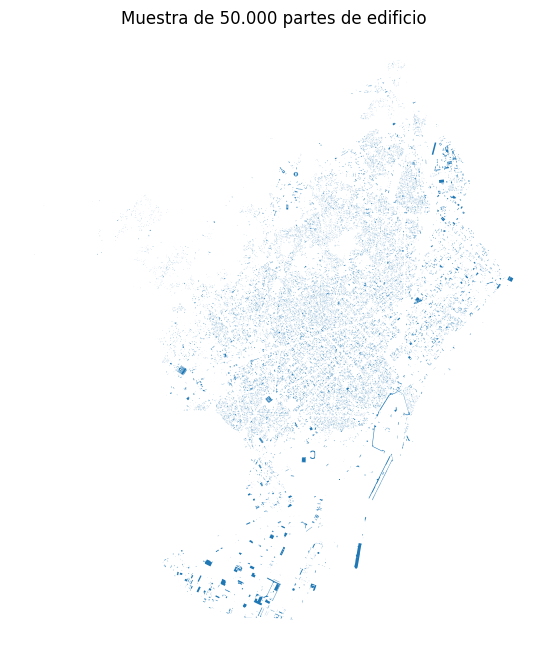

In [52]:
partes_edificios.sample(50000, random_state=1).plot(figsize=(8, 8), linewidth=0)   # dibujamos solo una muestra para que sea rápido
plt.title('Muestra de 50.000 partes de edificio')
plt.axis('off')
plt.show()

###**2.1.3. ¿Qué significa el identificador `localId`? parcela, manzana y parte**

Por ejemplo `0004702DF3800C_part3`, se lee así:

| Trozo | Qué significa |
|---|---|
| `00047` | **Manzana**: el bloque de edificios rodeado de calles (los 5 primeros dígitos) |
| `02` | **Parcela** dentro de esa manzana (los 2 dígitos siguientes) |
| `DF3800C` | Hoja del plano catastral donde está dibujada |
| `_part3` | **Parte** número 3 del edificio de esa parcela |

Los 14 primeros caracteres forman la **referencia catastral de la parcela**. Una parcela puede tener un edificio con **varias partes (volúmenes)**: por ejemplo, un cuerpo principal de 6 plantas, un anexo de 1 planta y un ático. Cada parte tiene su propia forma y su propio número de plantas.

Por tanto, las partes no son edificios distintos, y el número no es la manzana: es la parcela. La manzana son solo sus 5 primeros dígitos.

In [53]:
ids = partes_edificios[['localId', 'numberOfFloorsAboveGround']].copy()
ids['ref_parcela'] = ids['localId'].str[:14]                            # referencia catastral de la parcela
ids['ref_manzana'] = ids['localId'].str[:5]                             # los 5 primeros dígitos: manzana
ids['n_parte'] = ids['localId'].str.split('_part').str[1].astype(int)   # número de parte

print('Partes de edificio:', len(ids))
print('Parcelas distintas:', ids['ref_parcela'].nunique())

partes_por_parcela = ids.groupby('ref_parcela').size()
print('Partes por parcela: media', round(partes_por_parcela.mean(), 1), '| mediana', partes_por_parcela.median(), '| máximo', partes_por_parcela.max())
print('Parcelas con más de una parte (%):', round((partes_por_parcela > 1).mean() * 100, 1))

variacion = ids.groupby('ref_parcela')['numberOfFloorsAboveGround'].nunique()
varias = partes_por_parcela > 1
print('De las parcelas con varias partes, las que tienen partes con distinto número de plantas (%):', round((variacion[varias] > 1).mean() * 100, 1))

Partes de edificio: 319559
Parcelas distintas: 69911
Partes por parcela: media 4.6 | mediana 4.0 | máximo 280
Parcelas con más de una parte (%): 89.9
De las parcelas con varias partes, las que tienen partes con distinto número de plantas (%): 94.9


**Un ejemplo para verlo:**

Dibujamos **una parcela real** para ver mejor qué son las partes. A la izquierda cada parte con su número de plantas; a la derecha, todas las partes juntas formando la parcela.


In [54]:
ejemplo = partes_por_parcela[(partes_por_parcela == 5) & (variacion > 1)].index[0]
display(ids[ids['ref_parcela'] == ejemplo].sort_values('n_parte')[['localId', 'numberOfFloorsAboveGround']])

,localId,numberOfFloorsAboveGround
11,0005403DF3800E_part1,7
12,0005403DF3800E_part2,6
13,0005403DF3800E_part3,1
14,0005403DF3800E_part4,0
15,0005403DF3800E_part5,6


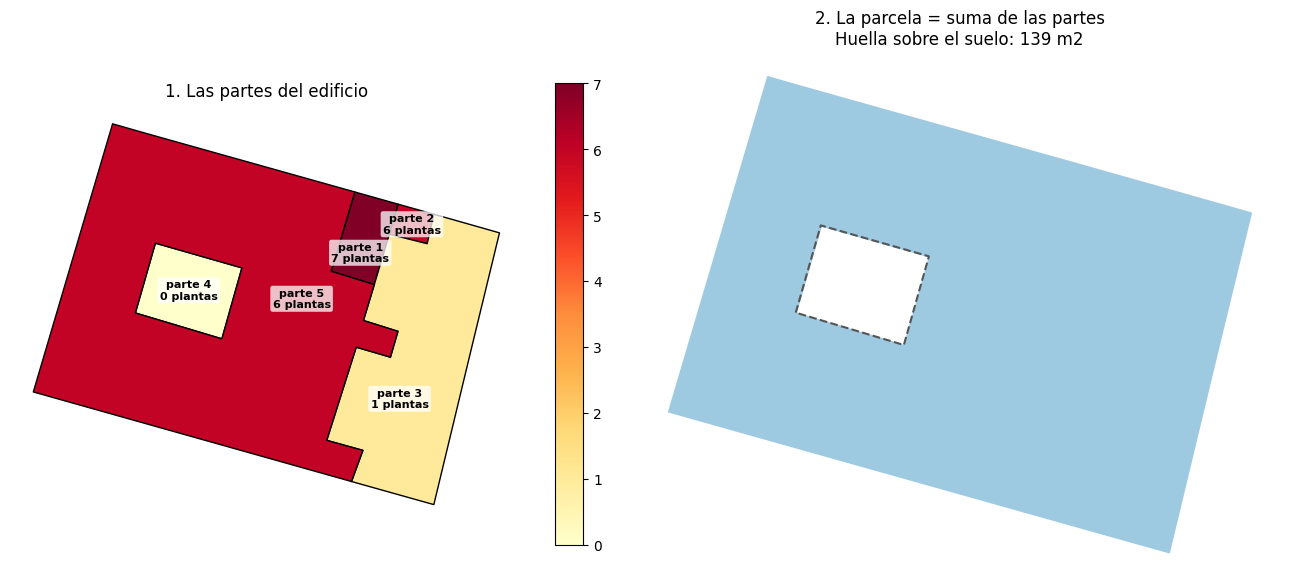

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))

# Filtramos las partes pertenecientes a la parcela de ejemplo especificada
parcela_ejemplo_id = ejemplo
partes_parcela_ejemplo = partes_edificios[partes_edificios['localId'].str.startswith(parcela_ejemplo_id)].copy()

# Añadimos un número de parte para las etiquetas
partes_parcela_ejemplo['parte'] = partes_parcela_ejemplo['localId'].str.split('_part').str[1].fillna('1')

# Panel 1: cada parte con un color según sus plantas
partes_parcela_ejemplo.plot(ax=ax[0], column='numberOfFloorsAboveGround', cmap='YlOrRd', edgecolor='black', legend=True, vmin=0)
for _, fila in partes_parcela_ejemplo.iterrows():
    p = fila.geometry.representative_point()                 # un punto dentro de la parte, para poner la etiqueta
    texto = f"parte {fila['parte']}\n{fila['numberOfFloorsAboveGround']} plantas"
    ax[0].annotate(texto, (p.x, p.y), ha='center', va='center', fontsize=8, fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.75))
ax[0].set_title('1. Las partes del edificio')
ax[0].axis('off')

# Panel 2: unimos las partes que tienen plantas en una sola forma
con_plantas = partes_parcela_ejemplo[partes_parcela_ejemplo['numberOfFloorsAboveGround'] > 0]
parcela = con_plantas.dissolve()                              # dissolve = fundir todas las formas en una
parcela.plot(ax=ax[1], color='#9ecae1', edgecolor='#9ecae1')

sin_plantas = partes_parcela_ejemplo[partes_parcela_ejemplo['numberOfFloorsAboveGround'] == 0]
if len(sin_plantas) > 0:                                      # las partes sin plantas, solo con contorno discontinuo
    sin_plantas.boundary.plot(ax=ax[1], color='#555555', linestyle='--')

ax[1].set_title(f"2. La parcela = suma de las partes\nHuella sobre el suelo: {parcela.geometry.area.iloc[0]:.0f} m2")
ax[1].axis('off')
plt.tight_layout()
plt.show()

##**2.2 Edificios**

In [56]:
inspeccionar(edificios, 'EDIFICIOS')

===== EDIFICIOS =====

Filas y columnas: (69911, 27)

Sistema de coordenadas: EPSG:25831

--- COLUMNAS EN LA TABLA EDIFICIOS ---
['gml_id', 'lowerCorner', 'upperCorner', 'beginLifespanVersion', 'conditionOfConstruction', 'beginning', 'end', 'endLifespanVersion', 'informationSystem', 'reference', 'localId', 'namespace', 'horizontalGeometryEstimatedAccuracy', 'horizontalGeometryEstimatedAccuracy_uom', 'horizontalGeometryReference', 'referenceGeometry', 'currentUse', 'numberOfBuildingUnits', 'numberOfDwellings', 'numberOfFloorsAboveGround', 'documentLink', 'format', 'sourceStatus', 'officialAreaReference', 'value', 'value_uom', 'geometry']

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 69911 entries, 0 to 69910
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype   
---  ------                                   --------------  -----   
 0   gml_id                                   69911 non-null  object  
 1   lowerCorner        

,gml_id,lowerCorner,upperCorner,beginLifespanVersion,conditionOfConstruction,beginning,end,endLifespanVersion,informationSystem,reference,localId,namespace,horizontalGeometryEstimatedAccuracy,horizontalGeometryEstimatedAccuracy_uom,horizontalGeometryReference,referenceGeometry,currentUse,numberOfBuildingUnits,numberOfDwellings,numberOfFloorsAboveGround,documentLink,format,sourceStatus,officialAreaReference,value,value_uom,geometry
0,ES.SDGC.BU.0004701DF3800C,429945.651 4580072.933,429973.141 4580093.773,2001-10-29T00:00:00,functional,1970-01-01T00:00:00,1970-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,0004701DF3800C,0004701DF3800C,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,1,1,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,346,m2,"POLYGON ((429972.94 4580072.933, 429946.7 4580..."
1,ES.SDGC.BU.0004702DF3800C,429884.2815 4580170.874,429920.1415 4580191.7435,2001-10-29T00:00:00,functional,1970-01-01T00:00:00,1970-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,0004702DF3800C,0004702DF3800C,ES.SDGC.BU,0.1,m,footPrint,True,4_3_publicServices,2,0,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,7366,m2,"MULTIPOLYGON (((429891.252 4580183.734, 429903..."
2,ES.SDGC.BU.0005401DF3800E,429944.683 4580384.3335,429957.873 4580404.9135,2001-10-29T00:00:00,functional,1975-01-01T00:00:00,1975-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,0005401DF3800E,0005401DF3800E,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,10,7,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,776,m2,"POLYGON ((429957.363 4580401.054, 429956.083 4..."
3,ES.SDGC.BU.0005403DF3800E,429969.453 4580395.3435,429986.2135 4580409.0335,2001-10-29T00:00:00,functional,1904-01-01T00:00:00,1904-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,0005403DF3800E,0005403DF3800E,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,12,10,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,709,m2,"POLYGON ((429981.014 4580406.584, 429982.574 4..."
4,ES.SDGC.BU.0005404DF3800E,429972.3035 4580406.1435,429988.9735 4580418.6935,2001-10-29T00:00:00,functional,1936-01-01T00:00:00,1936-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,0005404DF3800E,0005404DF3800E,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,20,17,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,926,m2,"POLYGON ((429987.824 4580410.624, 429987.164 4..."


,gml_id,lowerCorner,upperCorner,beginLifespanVersion,conditionOfConstruction,beginning,end,endLifespanVersion,informationSystem,reference,localId,namespace,horizontalGeometryEstimatedAccuracy,horizontalGeometryEstimatedAccuracy_uom,horizontalGeometryReference,referenceGeometry,currentUse,numberOfBuildingUnits,numberOfDwellings,numberOfFloorsAboveGround,documentLink,format,sourceStatus,officialAreaReference,value,value_uom,geometry
53577,ES.SDGC.BU.8511625DF2881B,428473.135 4580913.8755,428500.831 4580937.8335,2001-10-29T00:00:00,functional,1890-01-01T00:00:00,1890-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,8511625DF2881B,8511625DF2881B,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,1,1,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,280,m2,"POLYGON ((428488.219 4580930.064, 428492.365 4..."
370,ES.SDGC.BU.0022315DF3802C,429918.596 4582041.5265,429957.1355 4582079.9765,2001-10-29T00:00:00,functional,1900-01-01T00:00:00,1965-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,0022315DF3802C,0022315DF3802C,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,1,1,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,1383,m2,"POLYGON ((429936.526 4582068.986, 429939.106 4..."
61460,ES.SDGC.BU.9362719DF2896A,429310.763 4585924.283,429329.9945 4585944.499,2001-10-29T00:00:00,functional,1988-01-01T00:00:00,1988-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,9362719DF2896A,9362719DF2896A,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,8,7,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,740,m2,"POLYGON ((429315.513 4585937.621, 429317.5 458..."
1330,ES.SDGC.BU.0062246DF3806C,429892.9215 4586084.269,429901.0705 4586092.115,2001-10-29T00:00:00,functional,1930-01-01T00:00:00,1930-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,0062246DF3806C,0062246DF3806C,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,1,1,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,38,m2,"POLYGON ((429894.675 4586084.269, 429892.922 4..."
17805,ES.SDGC.BU.1334701DF3813C,431221.306 4583165.4985,431246.5265 4583190.5285,2001-10-29T00:00:00,functional,1973-01-01T00:00:00,1973-01-01T00:00:00,None,https://www1.sedecatastro.gob.es/CYCBienInmueb...,1334701DF3813C,1334701DF3813C,ES.SDGC.BU,0.1,m,footPrint,True,1_residential,26,20,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,2208,m2,"POLYGON ((431241.796 4583188.988, 431242.496 4..."


###**2.2.1. Uso del edificio: ¿residencial o industrial?**

La columna `currentUse` guarda el uso principal de cada edificio. La agrupamos en cuatro grupos: residencial, industrial, servicios públicos y otros (agricultura, oficinas y comercio).

In [57]:
print(edificios['currentUse'].value_counts())

currentUse
1_residential         61895
4_2_retail             2412
4_3_publicServices     1993
3_industrial           1751
4_1_office             1246
2_agriculture           195
Name: count, dtype: int64


**Qué mirar:** Podemos ver 4 grupos: **Residencial** (1_residential): 61.895 edificios, **Industrial** (3_industrial): 1.751 edificios, **Servicios públicos** (4_3_publicServices): 1.993 y **Otros** (2_agriculture + 4_1_office + 4_2_retail): 3.853 edificios.

### **2.2.2. Edificios sin uso asignado**

In [58]:
sin_uso = edificios[edificios['currentUse'].isna()]
print('Edificios sin uso:', len(sin_uso), '| % del total:', round(len(sin_uso) / len(edificios) * 100, 2))
print('% de la huella total:', round(sin_uso.geometry.area.sum() / edificios.geometry.area.sum() * 100, 2))
print(sin_uso['conditionOfConstruction'].value_counts(dropna=False))

Edificios sin uso: 419 | % del total: 0.6
% de la huella total: 2.74
conditionOfConstruction
-             331
functional     68
ruin           20
Name: count, dtype: int64


**Qué mirar**: 331 tienen -, 68 functional y 20 ruin. No sabemos qué significa -; parece un valor de relleno, pero es una suposición. Las 20 ruinas tienen sentido que no tengan uso. Los 68 funcionales y los 331 con - son huecos del dato, sin explicación. No los quitaremos ni inventaremos un uso, sino que los pondremos en un grupo aparte, **«sin dato»**. De esta forma, los porcentajes se podrán calcular sobre toda la superficie, y se podrá ver cuánto falta en cada barrio. Así residencial + industrial + servicios públicos + otros + sin dato suma 100.

### **2.2.3. Visualización de los usos de los edificios**

Actualizamos la columna `uso_grupo` para que los edificios con uso desconocido (`NaN`) queden clasificados de forma explícita como `sin_dato`. Después, representamos los 5 grupos finales en un gráfico de barras.

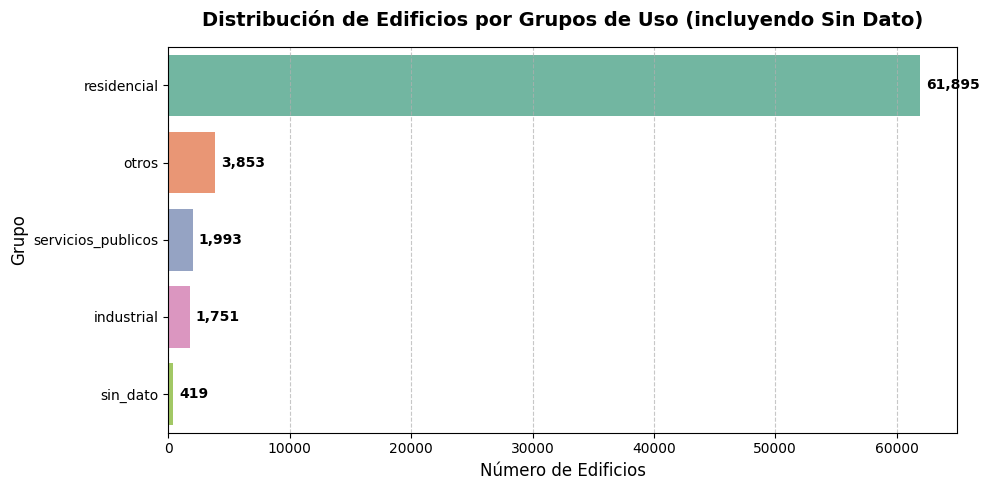

In [59]:
# Creamos el mapeo
edificios['uso_grupo'] = edificios['currentUse'].map({
    '1_residential': 'residencial',
    '3_industrial': 'industrial',
    '4_3_publicServices': 'servicios_publicos'
})

# Los nulos de currentUse pasan a ser 'sin_dato', y el resto de categorías (comercio, oficinas, etc.) pasan a ser 'otros'
edificios.loc[edificios['currentUse'].isna(), 'uso_grupo'] = 'sin_dato'
edificios['uso_grupo'] = edificios['uso_grupo'].fillna('otros')

# Calculamos los 5 grupos
conteo_grupos_completo = edificios['uso_grupo'].value_counts().reset_index()
conteo_grupos_completo.columns = ['Grupo de Uso', 'Cantidad']

# Creamos el gráfico de barras actualizado
plt.figure(figsize=(10, 5))
sns.barplot(data=conteo_grupos_completo, x='Cantidad', y='Grupo de Uso', palette='Set2', hue='Grupo de Uso', legend=False)

plt.title('Distribución de Edificios por Grupos de Uso (incluyendo Sin Dato)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Edificios', fontsize=12)
plt.ylabel('Grupo', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Añadimos los valores numéricos sobre cada barra
for index, row in conteo_grupos_completo.iterrows():
    plt.text(row['Cantidad'] + 500, index, f"{row['Cantidad']:,}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

###**2.2.4. Hacemos un mapa visual rápido para comprobarlo**

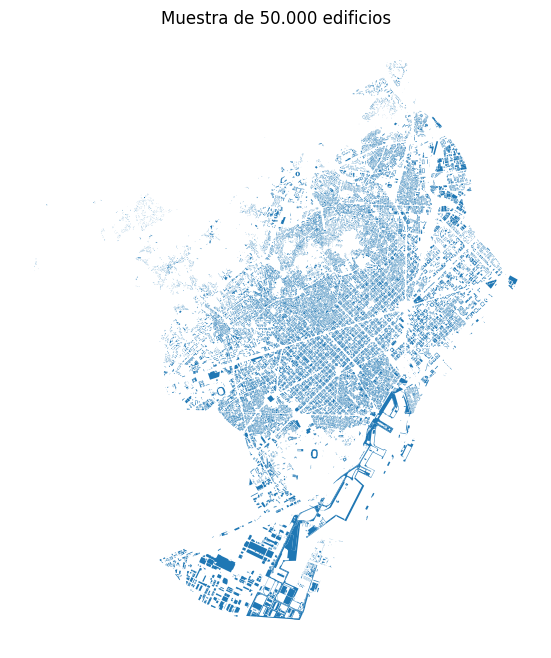

In [60]:
edificios.sample(50000, random_state=1).plot(figsize=(8, 8), linewidth=0)   # dibujamos solo una muestra para que sea rápido
plt.title('Muestra de 50.000 edificios')
plt.axis('off')
plt.show()

### **2.2.5. Y un mapa visual de edificios por categorías de uso**

Dibujamos un mapa con los edificios coloreando cada uno según su grupo de uso (`uso_grupo`) para comprobar su distribución espacial en Barcelona.

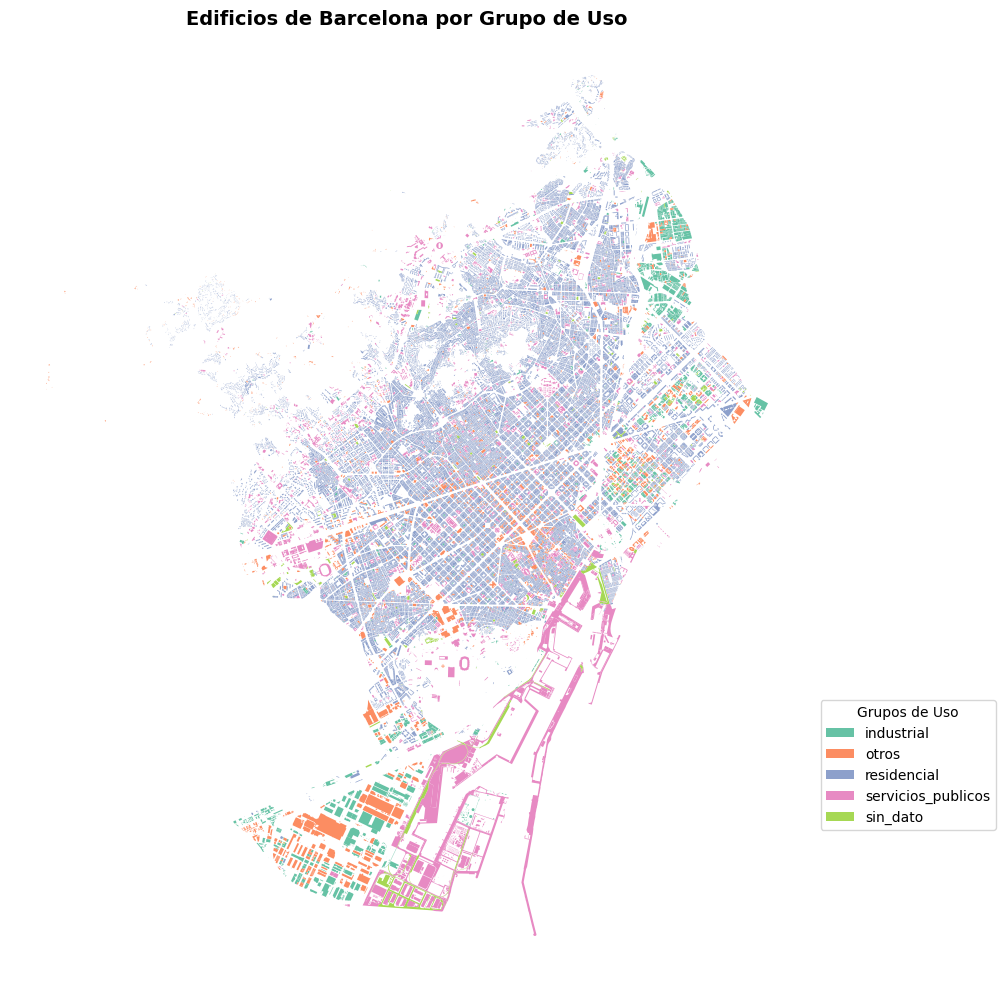

In [61]:
fig, ax = plt.subplots(figsize=(10, 10))
edificios.plot(
    ax=ax,
    column='uso_grupo',
    cmap='Set2',
    legend=True,
    legend_kwds={
        'title': "Grupos de Uso",
        'loc': 'lower right',
        'bbox_to_anchor': (1.25, 0.15)
    },
    linewidth=0
)

plt.title('Edificios de Barcelona por Grupo de Uso', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

## **2.3. Comprobación de identificadores únicos entre Edificios y Partes de Edificios**

Analizamos si el conjunto de referencias catastrales únicas en la tabla `edificios` es exactamente idéntico al conjunto obtenido a partir de `partes_edificios` (extrayendo los 14 primeros caracteres).

In [62]:
# Extraemos los conjuntos de IDs únicos
ids_partes_unicos = set(partes_edificios['localId'].str[:14].unique())
ids_edificios_unicos = set(edificios['localId'].unique())

print(f'IDs únicos en partes_edificios (14 chars): {len(ids_partes_unicos):,}')
print(f'IDs únicos en edificios:                  {len(ids_edificios_unicos):,}')

# Comprobamos si son exactamente iguales
son_iguales = ids_partes_unicos == ids_edificios_unicos
print(f'¿Son exactamente iguales ambos conjuntos?: {son_iguales}')

# Encontrar diferencias si las hay
solo_en_partes = ids_partes_unicos - ids_edificios_unicos
solo_en_edificios = ids_edificios_unicos - ids_partes_unicos

print(f'IDs que están en partes pero NO en edificios: {len(solo_en_partes)}')
print(f'IDs que están en edificios pero NO en partes: {len(solo_en_edificios)}')

if len(solo_en_partes) > 0:
    print('\nAlgunos ejemplos de IDs solo en partes:')
    print(list(solo_en_partes)[:5])

if len(solo_en_edificios) > 0:
    print('\nAlgunos ejemplos de IDs solo en edificios:')
    print(list(solo_en_edificios)[:5])

IDs únicos en partes_edificios (14 chars): 69,911
IDs únicos en edificios:                  69,911
¿Son exactamente iguales ambos conjuntos?: True
IDs que están en partes pero NO en edificios: 0
IDs que están en edificios pero NO en partes: 0


**Qué mirar**: Esto confirma que la relación es perfecta: cada edificio de la tabla `edificios` tiene mapeadas sus correspondientes partes (volúmenes) en la tabla `partes_edificios` utilizando la misma referencia de parcela de 14 caracteres.

##**2.4 Parcelas**

In [63]:
inspeccionar(parcelas, 'PARCELAS')

===== PARCELAS =====

Filas y columnas: (78371, 11)

Sistema de coordenadas: EPSG:25831

--- COLUMNAS EN LA TABLA PARCELAS ---
['gml_id', 'areaValue', 'areaValue_uom', 'beginLifespanVersion', 'endLifespanVersion', 'localId', 'namespace', 'label', 'nationalCadastralReference', 'pos', 'geometry']

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 78371 entries, 0 to 78370
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   gml_id                      78371 non-null  object  
 1   areaValue                   78371 non-null  int32   
 2   areaValue_uom               78371 non-null  object  
 3   beginLifespanVersion        78371 non-null  object  
 4   endLifespanVersion          0 non-null      object  
 5   localId                     78371 non-null  object  
 6   namespace                   78371 non-null  object  
 7   label                       78371 non-null  object  
 8   n

,gml_id,areaValue,areaValue_uom,beginLifespanVersion,endLifespanVersion,localId,namespace,label,nationalCadastralReference,pos,geometry
0,ES.SDGC.CP.000600100DF28D,136,m2,2019-06-17T00:00:00,None,000600100DF28D,ES.SDGC.CP,001,000600100DF28D,425743.14 4584428.43,"MULTIPOLYGON (((425748.748 4584428.072, 425745..."
1,ES.SDGC.CP.0995723DF3809F,52,m2,2011-11-11T00:00:00,None,0995723DF3809F,ES.SDGC.CP,723,0995723DF3809F,430899.34 4589247.86,"MULTIPOLYGON (((430905.872 4589243.3, 430902.6..."
2,ES.SDGC.CP.14943A9DF3819C,97,m2,2011-11-11T00:00:00,None,14943A9DF3819C,ES.SDGC.CP,3A9,14943A9DF3819C,431406.1 4589471.57,"MULTIPOLYGON (((431402.324 4589472.257, 431401..."
3,ES.SDGC.CP.1698209DF3819H,77,m2,2011-11-11T00:00:00,None,1698209DF3819H,ES.SDGC.CP,209,1698209DF3819H,431517.62 4589635.32,"MULTIPOLYGON (((431514.596 4589636.746, 431512..."
4,ES.SDGC.CP.1796113DF3819F,137,m2,2011-11-11T00:00:00,None,1796113DF3819F,ES.SDGC.CP,113,1796113DF3819F,431626.27 4589371,"MULTIPOLYGON (((431621.564 4589366.125, 431618..."


,gml_id,areaValue,areaValue_uom,beginLifespanVersion,endLifespanVersion,localId,namespace,label,nationalCadastralReference,pos,geometry
61925,ES.SDGC.CP.8609818DF2880H,240,m2,2008-11-25T00:00:00,None,8609818DF2880H,ES.SDGC.CP,18,8609818DF2880H,428585.98 4580707.84,"MULTIPOLYGON (((428591.36 4580717.874, 428595...."
77585,ES.SDGC.CP.9937403DF2893H,164,m2,2001-10-29T00:00:00,None,9937403DF2893H,ES.SDGC.CP,03,9937403DF2893H,429845.58 4583586.21,"MULTIPOLYGON (((429836.812 4583602.152, 429844..."
51458,ES.SDGC.CP.7408707DF2870G,153,m2,2001-10-29T00:00:00,None,7408707DF2870G,ES.SDGC.CP,07,7408707DF2870G,427370.02 4580613.01,"MULTIPOLYGON (((427379.351 4580618.474, 427380..."
24621,ES.SDGC.CP.1559209DF3815H,80,m2,2001-10-29T00:00:00,None,1559209DF3815H,ES.SDGC.CP,09,1559209DF3815H,431443.95 4585721.79,"MULTIPOLYGON (((431449.716 4585725.06, 431450...."
78178,ES.SDGC.CP.9975615DF2897F,1302,m2,2001-10-29T00:00:00,None,9975615DF2897F,ES.SDGC.CP,15,9975615DF2897F,429912.13 4587470.03,"MULTIPOLYGON (((429934.777 4587472.725, 429932..."


### **2.4.1 Identificadores repetidos**

Hay **309** filas marcadas como duplicadas si usamos la configuración por defecto de pandas (que no cuenta la primera aparición de cada ID).

Si analizamos el total de filas afectadas por estos duplicados (incluyendo sus primeras apariciones), encontramos **490 filas** en total correspondientes a **181 parcelas únicas**.

In [64]:
repetidas = parcelas[parcelas.duplicated(subset='localId', keep=False)]
print('Filas con localId repetido:', len(repetidas), '| parcelas afectadas:', repetidas['localId'].nunique())
display(repetidas.sort_values('localId')[['localId', 'areaValue']].head(6))

Filas con localId repetido: 490 | parcelas afectadas: 181


,localId,areaValue
3458,0066641DF3806E,186
3459,0066641DF3806E,13
6770,0293101DF3709C,9864
6771,0293101DF3709C,158528
6780,0303911DF3800C,5381
6781,0303911DF3800C,7240


**Qué mirar**: las filas repetidas no son copias porque el mismo localId aparece con áreas distintas. Parecen trozos de una misma parcela. Si borráramos filas perderíamos suelo. Por lo que luego uniremos las partes en vez de borrarlas.

###**2.4.2. Hacemos un mapa visual rápido para comprobarlo**

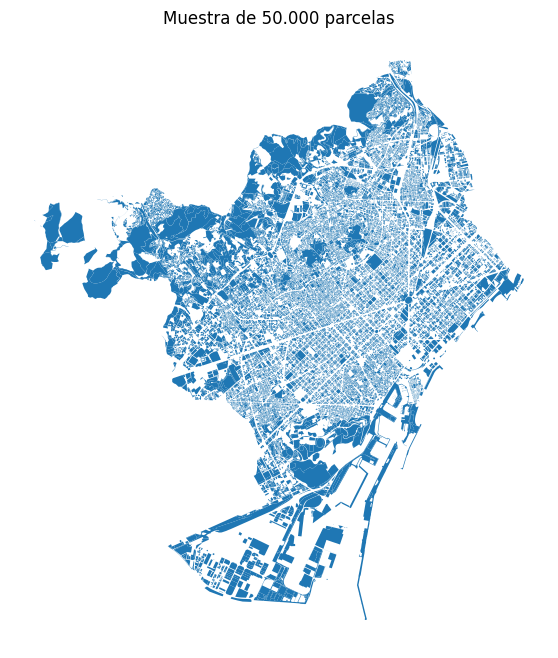

In [65]:
parcelas.sample(50000, random_state=1).plot(figsize=(8, 8), linewidth=0)   # dibujamos solo una muestra para que sea rápido
plt.title('Muestra de 50.000 parcelas')
plt.axis('off')
plt.show()

##**3. Limpieza**

###**3.1 Partes de edificio**

**3.1.1 Nos quedamos solo con lo que necesitamos y ponemos nombres claros**

In [66]:
edif_partes = partes_edificios[['localId', 'numberOfFloorsAboveGround', 'numberOfFloorsBelowGround', 'geometry']].copy()

# Nombres más cortos y fáciles de entender
edif_partes = edif_partes.rename(columns={
    'localId': 'id_parte',
    'numberOfFloorsAboveGround': 'plantas',
    'numberOfFloorsBelowGround': 'plantas_bajo',
})

print('Filas al empezar la limpieza:', len(edif_partes))

Filas al empezar la limpieza: 319559


**3.1.2 Quitamos las partes sin plantas sobre el suelo**

Las partes con 0 plantas sobre el suelo no son edificio visible: no suman altura, ni sombra, ni superficie construida. Y, no son sótanos: casi todas (el 99,5 %) tampoco tienen plantas bajo el suelo. Son partes sin planta, como patios interiores u otros espacios abiertos dentro de la parcela. Solo unas 235 tienen plantas subterráneas.

Las quitamos. Si las dejáramos, el porcentaje construido saldría inflado.

In [67]:
cero = edif_partes[edif_partes['plantas'] == 0]
print('Partes con 0 plantas sobre el suelo:', len(cero))
print('  de ellas, también sin plantas bajo el suelo:', (cero['plantas_bajo'] == 0).sum())
print('  de ellas, con plantas bajo el suelo:', (cero['plantas_bajo'] > 0).sum())

edif_partes = edif_partes[edif_partes['plantas'] > 0]
print('Filas ahora:', len(edif_partes))

Partes con 0 plantas sobre el suelo: 43053
  de ellas, también sin plantas bajo el suelo: 42818
  de ellas, con plantas bajo el suelo: 235
Filas ahora: 276506


**3.1.3 Revisamos los valores extremos**

Un valor de 100 plantas es casi seguro un error (las siguientes más altas rondan las 44 o 45). Primero miramos cuál es y luego decidimos.

In [68]:
raros = edif_partes[edif_partes['plantas'] > 50]
print('Partes con más de 50 plantas:')
display(raros[['id_parte', 'plantas']])

Partes con más de 50 plantas:


,id_parte,plantas
119303,2112401DF3821C_part25,100


**Decisión**: descartamos lo que supere 50 plantas

In [69]:
edif_partes = edif_partes[edif_partes['plantas'] <= 50]
print('Filas ahora:', len(edif_partes))

Filas ahora: 276505


**3.1.4 Creamos columnas nuevas y visualizamos la distribución**

- `ref_parcela`: los 14 primeros caracteres del identificador, que son la parcela a la que pertenece la parte.
- `altura_m`: altura aproximada, con **3 m por planta** (es una aproximación y hay que decirlo en la memoria).
- `huella_m2`: superficie que ocupa la parte en el suelo.
- `superficie_construida_m2`: huella × plantas, es decir, la suma de todas las plantas.

Para calcular superficies el mapa debe estar en **metros**. Lo comprobamos antes.

In [70]:
print('Unidad del mapa:', edif_partes.crs.axis_info[0].unit_name)

edif_partes['ref_parcela'] = edif_partes['id_parte'].str[:14]
edif_partes['altura_m'] = edif_partes['plantas'] * 3
edif_partes['huella_m2'] = edif_partes.geometry.area
edif_partes['superficie_construida_m2'] = edif_partes['huella_m2'] * edif_partes['plantas']

display(edif_partes[['plantas', 'altura_m', 'huella_m2', 'superficie_construida_m2']].describe().round(1))

pequenas = edif_partes['huella_m2'] < 5
print('Partes de menos de 5 m2:', pequenas.sum())
print('Su peso en la huella total (%):', round(edif_partes.loc[pequenas, 'huella_m2'].sum() / edif_partes['huella_m2'].sum() * 100, 2))

display(edif_partes.head())

Unidad del mapa: metre


,plantas,altura_m,huella_m2,superficie_construida_m2
count,276505.0,276505.0,276505.0,276505.0
mean,4.2,12.5,92.8,384.8
std,3.1,9.2,642.3,1164.1
min,1.0,3.0,0.0,0.0
25%,1.0,3.0,13.4,29.2
50%,4.0,12.0,36.3,115.1
75%,6.0,18.0,85.1,370.1
max,45.0,135.0,193753.8,193753.8


Partes de menos de 5 m2: 19550
Su peso en la huella total (%): 0.23


,id_parte,plantas,plantas_bajo,geometry,ref_parcela,altura_m,huella_m2,superficie_construida_m2
0,0004701DF3800C_part1,1,0,"POLYGON ((429972.94 4580072.933, 429946.7 4580...",0004701DF3800C,3,440.783155,440.783155
1,0004702DF3800C_part1,1,0,"POLYGON ((429916.262 4580171.284, 429912.582 4...",0004702DF3800C,3,25.294950,25.294950
2,0004702DF3800C_part2,1,0,"POLYGON ((429911.822 4580177.204, 429910.082 4...",0004702DF3800C,3,9.636100,9.636100
3,0004702DF3800C_part3,2,0,"POLYGON ((429893.992 4580173.604, 429897.022 4...",0004702DF3800C,6,85.611180,171.222360
4,0004702DF3800C_part4,2,0,"POLYGON ((429903.312 4580191.744, 429905.872 4...",0004702DF3800C,6,74.922185,149.844370


Las partes diminutas son muchas pero pesan muy poco en la huella total, así que **las dejamos**.

###**3.2 Edificios**

**3.2.1 Nos quedamos solo con lo que necesitamos y ponemos nombres claros**

De `edificios.gpkg` solo necesitamos dos cosas: su identificador (que es la referencia de la parcela) y su **uso**. El grupo de uso (`uso_grupo`) ya lo creamos en el apartado 2.2.3.

In [71]:
edif = edificios[['localId', 'currentUse', 'uso_grupo', 'geometry']].copy()
edif = edif.rename(columns={'localId': 'ref_parcela'})
edif['huella_m2'] = edif.geometry.area

print('Edificios:', len(edif))

display(edif['uso_grupo'].value_counts())
display(edif.head())

Edificios: 69911


,count
uso_grupo,
residencial,61895
otros,3853
servicios_publicos,1993
industrial,1751
sin_dato,419


,ref_parcela,currentUse,uso_grupo,geometry,huella_m2
0,0004701DF3800C,1_residential,residencial,"POLYGON ((429972.94 4580072.933, 429946.7 4580...",440.783155
1,0004702DF3800C,4_3_publicServices,servicios_publicos,"MULTIPOLYGON (((429891.252 4580183.734, 429903...",286.326865
2,0005401DF3800E,1_residential,residencial,"POLYGON ((429957.363 4580401.054, 429956.083 4...",152.677550
3,0005403DF3800E,1_residential,residencial,"POLYGON ((429981.014 4580406.584, 429982.574 4...",147.770320
4,0005404DF3800E,1_residential,residencial,"POLYGON ((429987.824 4580410.624, 429987.164 4...",130.866150


###**3.3 Parcelas**

**3.3.1 Nos quedamos solo con lo que necesitamos y ponemos nombres claros**

De la tabla de parcelas solo necesitamos el identificador y la forma. El área la calcularemos nosotras desde el mapa. Además, conviene quedarse solo con estas dos columnas antes de unir los trozos, porque al unirlos, las demás columnas conservarían el valor del primer trozo, que sería incorrecto (por ejemplo, `areaValue` tendría solo el área de un trozo).

Renombramos `localId` a `ref_parcela`, igual que en las partes y en los edificios, para que los tres archivos hablen el mismo idioma.

In [72]:
parce = parcelas[['localId', 'geometry']].copy()
parce = parce.rename(columns={'localId': 'ref_parcela'})

print('Filas al empezar la limpieza:', len(parce))

Filas al empezar la limpieza: 78371


**3.3.2 Unimos los trozos de una misma parcela con `dissolve`**

`dissolve` (fundir) agrupa las filas que tienen el mismo valor en una columna (aquí, `ref_parcela`) y **junta sus formas en una sola**. Si una parcela está partida en 3 trozos, pasa a ser 1 fila con la forma completa. Las parcelas que ya eran una sola fila se quedan igual. Con `as_index=False`, `ref_parcela` sigue siendo una columna normal.

Después calculamos el área de cada parcela desde su forma.

In [73]:
parce = parce.dissolve(by='ref_parcela', as_index=False)
parce['area_parcela_m2'] = parce.geometry.area

print('Parcelas tras unir los trozos:', len(parce))
print('Suma de áreas, columna areaValue (km2):', round(parcelas['areaValue'].sum() / 1_000_000, 1))
print('Suma de áreas, calculada del mapa (km2):', round(parce['area_parcela_m2'].sum() / 1_000_000, 1))

# Una de las parcelas partidas que vimos en 2.4.1: antes eran dos filas (9.864 y 158.528 m2)
display(parce[parce['ref_parcela'] == '0293101DF3709C'])

Parcelas tras unir los trozos: 78062
Suma de áreas, columna areaValue (km2): 81.6
Suma de áreas, calculada del mapa (km2): 81.6


,ref_parcela,geometry,area_parcela_m2
4790,0293101DF3709C,"MULTIPOLYGON (((430397.522 4579323.512, 430363...",168391.865608


**Qué mirar:** las dos sumas de área son iguales, y la parcela de ejemplo ahora es **una sola fila** con un área cercana a la suma de sus dos trozos (9.864 + 158.528 m²). Esto nos demuestra que al unir no hemos perdido suelo.

## **4. Asignamos cada elemento a su barrio**

Ni las partes, ni los edificios, ni las parcelas traen el barrio. Se lo damos **por su posición en el mapa** con `sjoin` (**unión espacial**).

Como las partes, los edificios y las parcelas comparten la **referencia de parcela de 14 caracteres**, hacemos **un solo cruce**: cada edificio (que es una parcela) se asigna a su barrio por su punto central, y todo lo demás hereda ese barrio. Así toda la información de una misma parcela va al mismo barrio.

###**4.1 Cada edificio a su barrio**

In [74]:
puntos = edif[['ref_parcela', 'geometry']].copy()
puntos['geometry'] = puntos.geometry.centroid            # sustituimos cada forma por su punto central

cruce = gpd.sjoin(puntos, barrios[['codi_barri', 'geometry']], how='left', predicate='within')
cruce = cruce[~cruce.index.duplicated()]                 # por si algún punto cae justo en el límite de dos barrios

print('Edificios:', len(puntos), '| filas tras el cruce:', len(cruce), '(deben ser las mismas)')
print('Edificios sin barrio:', cruce['codi_barri'].isna().sum())

Edificios: 69911 | filas tras el cruce: 69911 (deben ser las mismas)
Edificios sin barrio: 8


**4.1.1 Edificios sin barrio**

Identificamos los edificios que se quedaron sin barrio asignado. Su punto central cae justo fuera de los límites (en el borde de la ciudad o junto al mar). Primero los miramos y luego los asignamos al **barrio más cercano** con `sjoin_nearest`, comprobando a qué distancia está.

In [75]:
sin_barrio = cruce.index[cruce['codi_barri'].isna()]
display(edif.loc[sin_barrio, ['ref_parcela', 'uso_grupo', 'huella_m2']])

cercano = gpd.sjoin_nearest(puntos.loc[sin_barrio], barrios[['codi_barri', 'geometry']],
                            how='left', distance_col='distancia_m')
cercano = cercano[~cercano.index.duplicated()]
display(cercano[['ref_parcela', 'codi_barri', 'distancia_m']].round(1))

,ref_parcela,uso_grupo,huella_m2
15418,1185901DF3718E,servicios_publicos,432734.913937
24723,1813202DF3811D,servicios_publicos,139837.706089
24724,1813203DF3811D,servicios_publicos,6699.351139
28043,2112403DF3821C,sin_dato,76719.932885
28044,2112405DF3821C,servicios_publicos,3621.844119
28881,2204323DF3820C,servicios_publicos,9182.702262
28882,2204324DF3820C,servicios_publicos,33464.075104
28885,2204328DF3820C,servicios_publicos,2069.866856


,ref_parcela,codi_barri,distancia_m
15418,1185901DF3718E,12,50.9
24723,1813202DF3811D,2,39.0
24724,1813203DF3811D,2,16.6
28043,2112403DF3821C,3,1.5
28044,2112405DF3821C,3,16.0
28881,2204323DF3820C,3,18.8
28882,2204324DF3820C,3,61.5
28885,2204328DF3820C,3,35.0


**Qué mirar**: Vemos que están a pocos metros de algún barrio por lo que asignarlos a ese barrio es razonable.

In [76]:
LIMITE_DISTANCIA_M = 100

cercanos_ok = cercano[cercano['distancia_m'] <= LIMITE_DISTANCIA_M]
cruce.loc[cercanos_ok.index, 'codi_barri'] = cercanos_ok['codi_barri']

print('Edificios asignados al barrio más cercano:', len(cercanos_ok))
print('Edificios que siguen sin barrio:', cruce['codi_barri'].isna().sum())

Edificios asignados al barrio más cercano: 8
Edificios que siguen sin barrio: 0


**4.1.2 Asignación de barrio**

Señalamos dónde están esos 8 edificios y qué barrio se les asigna

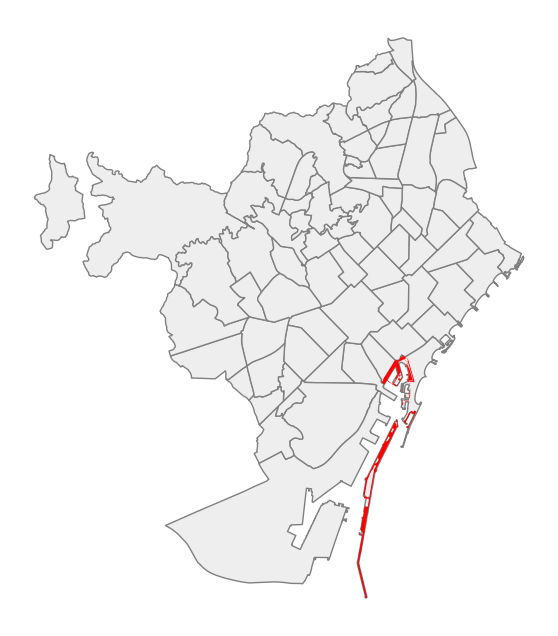

,codi_barri,nom_barri
1,2,el Barri Gòtic
2,3,la Barceloneta
11,12,la Marina del Prat Vermell


In [77]:
# ¿Dónde están? Los 8 edificios (en rojo) sobre los barrios
fig, ax = plt.subplots(figsize=(8, 8))
barrios.plot(ax=ax, color='#eeeeee', edgecolor='grey')
edif.loc[sin_barrio].plot(ax=ax, color='red')
ax.axis('off')
plt.show()

# ¿A qué barrios van?
display(barrios[barrios['codi_barri'].isin(cercano['codi_barri'])][['codi_barri', 'nom_barri']])

###**4.2 Las partes, los edificios y las parcelas heredan el barrio**

Creamos una tabla de apoyo «parcela → barrio» y la usamos con `map`.

En nuestros datos originales, ni las partes de edificio, ni los edificios, ni las parcelas sabían a qué barrio pertenecían. Sin embargo, todos ellos comparten un elemento común: la **referencia catastral de la parcela** (ref_parcela de 14 caracteres).

Para no tener que hacer un cruce espacial geométrico pesado (gpd.sjoin) de millones de polígonos de parcelas y partes contra los barrios, tomamos los puntos centrales de los edificios, localizamos su barrio espacialmente una sola vez y guardamos ese resultado en un DataFrame pequeño (cruce).

In [78]:
barrio_de_la_parcela = cruce.set_index('ref_parcela')['codi_barri']

edif['codi_barri']       = edif['ref_parcela'].map(barrio_de_la_parcela)
edif_partes['codi_barri'] = edif_partes['ref_parcela'].map(barrio_de_la_parcela)
parce['codi_barri']       = parce['ref_parcela'].map(barrio_de_la_parcela)

# Cada parte tiene el uso de su edificio: así medimos el uso por superficie realmente construida
edif_partes['uso_grupo'] = edif_partes['ref_parcela'].map(edif.set_index('ref_parcela')['uso_grupo'])

print('Partes sin barrio:  ', edif_partes['codi_barri'].isna().sum())
print('Edificios sin barrio:', edif['codi_barri'].isna().sum())
print('Parcelas sin barrio: ', parce['codi_barri'].isna().sum(),)

Partes sin barrio:   0
Edificios sin barrio: 0
Parcelas sin barrio:  8154


**4.2.1 ¿Por qué quedaron 8.154 parcelas sin barrio originalmente?**

Al construir nuestra **tabla de apoyo** (`barrio_de_la_parcela`), asociamos cada parcela al barrio utilizando únicamente los puntos centrales de los **edificios** (`edif`). Esto significa que:

* Barcelona tiene **78.062 parcelas** en total, pero solo **69.911 edificios** (parcelas edificadas).
* Las **8.154 parcelas restantes** corresponden a espacios vacíos, solares, parques, patios o infraestructuras públicas **que no contienen ningún edificio**.
* Al no tener un edificio asociado, estas parcelas vacías no figuraban en la tabla de apoyo y quedaron marcadas temporalmente como `NaN` (sin barrio).

**4.2.2 Asignación de las parcelas vacías por posición geográfica**

Para asignar estas parcelas sin edificar a su respectivo barrio, realizamos un cruce espacial directo entre la geometría de la parcela (usando su punto representativo interno para evitar conflictos de fronteras) y los polígonos de los barrios.

In [79]:
# Identificamos las parcelas que no tienen barrio asignado
parcelas_sin_barrio = parce[parce['codi_barri'].isna()].copy()

# Generamos su punto representativo interno
parcelas_sin_barrio['geometry_point'] = parcelas_sin_barrio.geometry.representative_point()
puntos_parcelas = parcelas_sin_barrio.set_geometry('geometry_point')[['ref_parcela', 'geometry_point']]

# Cruzamos espacialmente buscando qué punto cae exactamente 'dentro' de cada barrio
cruce = gpd.sjoin(
    puntos_parcelas,
    barrios[['codi_barri', 'geometry']],
    how='left',
    predicate='within'
)
cruce = cruce[~cruce.index.duplicated()]

# Asignamos estos barrios a la tabla principal 'parce'
mapeo = cruce.set_index('ref_parcela')['codi_barri']
parce['codi_barri'] = parce['codi_barri'].fillna(parce['ref_parcela'].map(mapeo))

print('Parcelas sin barrio:', parce['codi_barri'].isna().sum())

Parcelas sin barrio: 28


**4.2.3 Asignación de parcelas fronterizas por proximidad (`sjoin_nearest`)**

Como hemos observado, quedan exactamente **28 parcelas** sin asignar porque se encuentran situadas en los límites exteriores de la costa o el municipio, donde los micro-desajustes de digitalización hacen que su punto caiga fuera de los polígonos de los barrios.

Para solucionar este detalle, buscamos y asignamos estas parcelas restantes al barrio colindante más cercano.

In [80]:
# Identificamos las 28 parcelas
restantes = parce[parce['codi_barri'].isna()].copy()

if len(restantes) > 0:
    # Obtenemos sus puntos representativos
    restantes['geometry_point'] = restantes.geometry.representative_point()
    puntos_restantes = restantes.set_geometry('geometry_point')[['ref_parcela', 'geometry_point']]

    # Buscamos el barrio más cercano con sjoin_nearest
    cruce2= gpd.sjoin_nearest(
        puntos_restantes,
        barrios[['codi_barri', 'geometry']],
        how='left'
    )
    cruce2= cruce2[~cruce2.index.duplicated()]

    # Consolidamos la asignación definitiva
    mapeo2 = cruce2.set_index('ref_parcela')['codi_barri']
    parce['codi_barri'] = parce['codi_barri'].fillna(parce['ref_parcela'].map(mapeo2))

print('Parcelas sin barrio:', parce['codi_barri'].isna().sum())

Parcelas sin barrio: 0


## **5. Variables por barrio**

Para poder analizar Barcelona a nivel de sus **73 barrios**, necesitamos resumir la enorme cantidad de información espacial detallada (cientos de miles de registros de edificios y parcelas) en indicadores clave agregados.

Para hacerlo de forma limpia, eficiente y ordenada, seguimos la estrategia de **"divide y vencerás"**: agrupamos los datos con `groupby('codi_barri')` y generamos tres tablas independientes según su fuente de origen original, las cuales fusionaremos más adelante con `merge`.

La **altura media** se **pondera por huella**: los edificios que ocupan más suelo pesan más. Por eso multiplicamos cada altura por su huella y dividimos entre la huella total.

### **5.1 Una tabla por cada fuente**

**5.1.1 Tabla de Edificación (`por_barrio`):**

Extrae métricas de volumen, forma y escala física de los edificios (número de inmuebles, total de metros cuadrados de huella sobre el suelo, superficie total construida sumando todas sus plantas y la altura media ponderada).

In [81]:
edif_partes['altura_x_huella'] = edif_partes['altura_m'] * edif_partes['huella_m2']

por_barrio = edif_partes.groupby('codi_barri').agg(
    n_edificios=('ref_parcela', 'nunique'),
    huella_total_m2=('huella_m2', 'sum'),
    superficie_construida_m2=('superficie_construida_m2', 'sum'),
    altura_x_huella=('altura_x_huella', 'sum'),
).reset_index()

**5.1.2 Tabla de Ocupación de Suelo (`ocupacion`):**

Compara de manera realista la porción de suelo privado construida frente al suelo total disponible de las parcelas que sí contienen edificios. Esto nos permite obtener la tasa neta de ocupación parcelaria, excluyendo zonas públicas como calles o parques.

In [82]:
huella_por_parcela = edif_partes.groupby('ref_parcela')['huella_m2'].sum().rename('huella_parcela_m2')

parce_con_edificio = parce.merge(huella_por_parcela, left_on='ref_parcela', right_index=True, how='inner')

# La huella no puede ser mayor que la parcela (pequeños desajustes de dibujo)
parce_con_edificio['huella_parcela_m2'] = parce_con_edificio['huella_parcela_m2'].clip(
    upper=parce_con_edificio['area_parcela_m2'])

ocupacion = parce_con_edificio.groupby('codi_barri').agg(
    area_parcelas_m2=('area_parcela_m2', 'sum'),
    huella_parcelas_m2=('huella_parcela_m2', 'sum'),
).reset_index()

print('Parcelas con edificio:', len(parce_con_edificio))

Parcelas con edificio: 69768


**Qué mirar**: De las **69.911** parcelas que originalmente tenían algún tipo de construcción en Barcelona, finalmente nos quedamos con **69.768** al calcular la ocupación real del suelo.

Esta pequeña diferencia (solo el **0,2%** de los datos) se debe a que eliminamos elementos auxiliares que no tienen plantas sobre el nivel del suelo (como patios internos, cubas de agua, claraboyas o parkings subterráneos puros). Por lo tanto, el resultado es totalmente coherente, preciso y representa únicamente el suelo ocupado por edificaciones reales visibles.

**5.1.3 Tabla de Usos del Suelo (`usos`):**

Traduce el total de huella edificada a porcentajes de actividades predominantes (residencial, industrial, equipamientos públicos, etc.)

In [83]:
# Uso, medido por superficie construida de las partes (no por número de edificios)
GRUPOS = ['residencial', 'industrial', 'servicios_publicos', 'otros', 'sin_dato']

huella_por_uso = edif_partes.pivot_table(index='codi_barri', columns='uso_grupo', values='huella_m2',
                                         aggfunc='sum', fill_value=0)
huella_por_uso = huella_por_uso.reindex(columns=GRUPOS, fill_value=0)
total_uso = huella_por_uso.sum(axis=1)

usos = pd.DataFrame({
    'pct_residencial':        huella_por_uso['residencial'] / total_uso * 100,
    'pct_industrial':         huella_por_uso['industrial'] / total_uso * 100,
    'pct_servicios_publicos': huella_por_uso['servicios_publicos'] / total_uso * 100,
    'pct_otros':              huella_por_uso['otros'] / total_uso * 100,
    'pct_sin_dato':           huella_por_uso['sin_dato'] / total_uso * 100,
}).reset_index()

suma = usos.drop(columns='codi_barri').sum(axis=1)
print('Los 5 grupos suman 100 en todos los barrios:', ((suma - 100).abs() < 1e-6).all())

print('Barrio con más huella sin uso (%):', round(usos['pct_sin_dato'].max(), 1))

Los 5 grupos suman 100 en todos los barrios: True
Barrio con más huella sin uso (%): 5.7


**Qué mirar:** El hecho de que el barrio con mayor porcentaje de huella sin uso asignado alcance apenas un **5.7%** es una excelente noticia metodológica.

Esto demuestra que **más del 94.3% de la superficie edificada en todos los barrios de Barcelona está perfectamente clasificada** en el catastro. Este nivel de cobertura tan elevado garantiza que los análisis de usos del suelo (residencial, comercial, industrial) son estadísticamente sólidos, representativos y suficientemente completos para poder analizar la información.



### **5.2 Juntamos todo y calculamos las variables finales**

In [84]:
barrios['area_barrio_m2'] = barrios.geometry.area

tabla = barrios[['codi_barri', 'nom_barri', 'area_barrio_m2']]
tabla = tabla.merge(por_barrio, on='codi_barri', how='left')
tabla = tabla.merge(ocupacion, on='codi_barri', how='left')
tabla = tabla.merge(usos, on='codi_barri', how='left')

tabla['area_barrio_km2']       = tabla['area_barrio_m2'] / 1_000_000
tabla['altura_media_m']        = tabla['altura_x_huella'] / tabla['huella_total_m2']
tabla['pct_construido']        = tabla['huella_total_m2'] / tabla['area_barrio_m2'] * 100
tabla['edificabilidad']        = tabla['superficie_construida_m2'] / tabla['area_barrio_m2']
tabla['edificios_por_km2']     = tabla['n_edificios'] / tabla['area_barrio_km2']
tabla['pct_ocupacion_parcela'] = tabla['huella_parcelas_m2'] / tabla['area_parcelas_m2'] * 100

VARIABLES = ['n_edificios', 'huella_total_m2', 'superficie_construida_m2', 'altura_media_m',
             'pct_construido', 'edificabilidad', 'edificios_por_km2', 'pct_ocupacion_parcela',
             'pct_residencial', 'pct_industrial', 'pct_servicios_publicos', 'pct_otros', 'pct_sin_dato']

display(tabla[['nom_barri'] + VARIABLES].head())

,nom_barri,n_edificios,huella_total_m2,superficie_construida_m2,altura_media_m,pct_construido,edificabilidad,edificios_por_km2,pct_ocupacion_parcela,pct_residencial,pct_industrial,pct_servicios_publicos,pct_otros,pct_sin_dato
0,el Raval,1921,571019.198621,2.581461e+06,13.562387,51.897337,2.346173,1745.909484,73.317336,65.766678,0.151158,21.858314,12.043447,0.180403
1,el Barri Gòtic,1322,413118.919241,1.949935e+06,14.160099,50.652525,2.390816,1620.904642,65.578764,56.622765,0.035984,21.895091,20.621111,0.825049
2,la Barceloneta,929,239273.887765,1.011822e+06,12.686159,20.288074,0.857926,787.700710,29.842123,41.784580,0.250045,47.068358,10.253554,0.643463
3,"Sant Pere, Santa Caterina i la Ribera",1514,399947.082235,1.812244e+06,13.593629,36.042023,1.633140,1364.371088,51.557713,65.119495,2.466175,22.658293,9.678891,0.077145
4,el Fort Pienc,677,344312.728243,1.934953e+06,16.859261,37.048538,2.082037,728.461601,67.348308,73.218055,2.894268,13.801065,10.086612,0.000000


**5.2.1 Calculamos el impacto territorial de usos sobre el total de barrios**

¿Por qué utilizar los dos tipos de porcentajes: Composición vs. Ocupación Territorial?

Para comprender correctamente el tejido de Barcelona y evitar graves distorsiones visuales en los mapas, trabajamos con dos tipos de indicadores para cada uso del suelo:

* **Composición Edificada (`pct_residencial`, `pct_industrial`):** Mide la especialización de las construcciones.
  * **¿Qué responde?:** *De todo lo que se ha construido en este barrio, ¿qué porcentaje es residencial o industrial?*
   * **Caso práctico:** Es idóneo para clasificar la tipología del tejido urbano (si un barrio es puramente residencial o es un nodo industrial/servicios), sin importar el tamaño del barrio ni si tiene grandes parques o zonas forestales alrededor.

* **Ocupación Territorial Real (`pct_residencial_real_barrio`, `pct_industrial_real_barrio`):** Mide la ocupación física real del suelo del barrio.
  * **¿Qué responde?:** *Qué porcentaje de la superficie total del barrio está físicamente cubierta por viviendas o industrias?*
   * **Caso práctico:** Es la métrica ideal para los análisis ambientales y microclimáticos. Si un barrio boscoso tiene un 90% de residencial pero solo un 1% de su suelo construido, el impacto de su masa residencial real sobre la absorción de calor de la tierra es apenas del 0.9%, evitando falsas interpretaciones en los mapas de calor urbano.

Por tanto, ambos indicadores deben coexistir porque responden a dos preguntas de planificación urbana completamente distintas: uno describe el perfil de las construcciones y el otro describe la densidad real en el territorio urbano.

In [85]:
# Calculamos el impacto territorial real de todos los usos clave sobre la superficie total del barrio
tabla['pct_residencial_real_barrio'] = (tabla['pct_residencial'] / 100) * tabla['pct_construido']
tabla['pct_industrial_real_barrio'] = (tabla['pct_industrial'] / 100) * tabla['pct_construido']
tabla['pct_servicios_publicos_real_barrio'] = (tabla['pct_servicios_publicos'] / 100) * tabla['pct_construido']

# Actualizamos el listado global de variables para exportar e integrar todos los indicadores en el archivo definitivo
nuevas_variables = ['pct_residencial_real_barrio', 'pct_industrial_real_barrio', 'pct_servicios_publicos_real_barrio']
for var in nuevas_variables:
    if var not in VARIABLES:
        VARIABLES.append(var)

print("Indicadores territoriales reales calculados con éxito para todos los usos.")

Indicadores territoriales reales calculados con éxito para todos los usos.


**5.2.2 ¿Qué significa cada variable?**

| Variable | Qué mide | Por qué importa / Utilidad práctica |
|---|---|---|
| `pct_construido` | % del barrio cubierto físicamente por edificios | Permite analizar la impermeabilización general del suelo y el potencial de absorción de calor. |
| `altura_media_m` | Altura media de las estructuras edificadas | Esencial para evaluar la sombra proyectada, la ventilación del viento y el efecto de "cañón urbano". |
| `edificabilidad` | m² construidos por cada m² del barrio | Mide la densidad volumétrica o masa construida total. |
| `edificios_por_km2` | Densidad de edificios por unidad de superficie | Ayuda a comprender la densidad de la urbanización. |
| `pct_ocupacion_parcela` | % de superficie edificada dentro de parcelas privadas | Muestra el grado de aprovechamiento privado de las parcelas (patios y jardines privados vs. asfalto). |
| `pct_residencial` / `pct_industrial` | % del uso respecto al total edificado (Composición) | Identifica la vocación del barrio (zona residencial, zona industrial, barrio mixto). |
| `pct_residencial_real_barrio` / `pct_industrial_real_barrio` | % de ocupación del uso sobre la superficie total del barrio | Evita distorsiones espaciales en mapas de densidad y microclima (como la distorsión de Collserola). |
| `pct_servicios_publicos` / `pct_otros` / `pct_sin_dato` | % de la huella de cada grupo | Completa el reparto de usos (suman 100 con residencial e industrial). |

> ⚠️ **Nota de interpretación:** El `pct_construido` incluye el área total del barrio administrativo, incluyendo bosques o grandes zonas verdes públicas (como Collserola o Montjuïc). Un barrio de montaña parecerá poco denso a nivel general en `pct_construido`, pero la variable `pct_ocupacion_parcela` nos revelará si sus áreas urbanas consolidadas internas son realmente densas o no. Por eso, al comparar el `% construido` global con la `pct_ocupacion_parcela` y los indicadores de `% real_barrio`, se puede discernir al instante si un barrio es poco denso porque sus parcelas tienen muchos jardines y patios libres, o si se debe simplemente a la presencia de grandes pulmones verdes públicos y bosques dentro de sus fronteras administrativas.

*Por ejemplo: el `pct_construido` del 1,8% en Vallvidrera no significa que sus casas estén muy espaciadas entre sí, sino que el barrio es mayoritariamente bosque.*

## **6. Comprobaciones**

Antes de guardar, hacemos algunas comprobaciones para ver que todo es coherente.

In [86]:
print('Barrios:', len(tabla), '(deben ser 73)')
print('Huella total (km2):', round(tabla['huella_total_m2'].sum() / 1_000_000, 1))

print('Códigos de barrio repetidos:', tabla['codi_barri'].duplicated().sum())

nulos = tabla[VARIABLES].isna().sum()
print('Variables con valores vacíos:')
print(nulos)

display(tabla[VARIABLES].describe().round(1))

Barrios: 73 (deben ser 73)
Huella total (km2): 25.7
Códigos de barrio repetidos: 0
Variables con valores vacíos:
n_edificios                           0
huella_total_m2                       0
superficie_construida_m2              0
altura_media_m                        0
pct_construido                        0
edificabilidad                        0
edificios_por_km2                     0
pct_ocupacion_parcela                 0
pct_residencial                       0
pct_industrial                        0
pct_servicios_publicos                0
pct_otros                             0
pct_sin_dato                          0
pct_residencial_real_barrio           0
pct_industrial_real_barrio            0
pct_servicios_publicos_real_barrio    0
dtype: int64


,n_edificios,huella_total_m2,superficie_construida_m2,altura_media_m,pct_construido,edificabilidad,edificios_por_km2,pct_ocupacion_parcela,pct_residencial,pct_industrial,pct_servicios_publicos,pct_otros,pct_sin_dato,pct_residencial_real_barrio,pct_industrial_real_barrio,pct_servicios_publicos_real_barrio
count,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0
mean,955.8,351652.9,1457619.1,13.1,30.9,1.4,1073.8,55.0,71.8,6.1,12.6,8.8,0.7,23.1,1.7,3.2
std,715.9,421546.7,1170876.5,3.3,14.6,0.8,856.8,20.7,20.0,12.7,11.8,7.6,1.3,13.9,4.2,2.4
min,29.0,23683.9,64317.5,4.5,1.8,0.0,38.1,5.4,2.1,0.0,1.5,0.0,0.0,0.5,0.0,0.2
25%,494.0,141705.0,531000.5,11.6,19.4,0.8,419.7,37.1,64.6,0.5,5.6,3.1,0.0,11.1,0.1,1.6
50%,722.0,256005.0,1182784.0,13.5,32.9,1.3,911.1,58.4,79.2,1.6,8.2,6.2,0.2,23.5,0.5,2.6
75%,1350.0,423676.0,1949934.9,15.8,42.3,2.1,1602.9,71.8,85.3,3.2,14.2,12.1,0.6,34.3,1.0,4.2
max,3707.0,3398720.1,5732433.4,20.8,59.1,3.0,5333.5,86.7,95.0,72.8,68.5,35.2,5.7,50.3,29.4,11.3


**Qué mirar:**

* **73 Barrios analizados:** El número es exacto, lo que confirma que ningún barrio de Barcelona se ha quedado fuera ni se ha duplicado durante las uniones espaciales.
* **25.7 km² de huella edificada:** Representa la superficie que realmente ocupan los edificios tocando el suelo en toda Barcelona.
* **0 datos vacíos (NaN):** Todas las variables se calcularon correctamente para todos los barrios, garantizando una base de datos 100% limpia y lista para analizar.

**Calculamos algunos valores para tener una primera visión de los datos:**

In [87]:
columnas = ['nom_barri', 'pct_construido', 'pct_ocupacion_parcela', 'altura_media_m', 'edificabilidad']

print('Los 5 barrios con MÁS % construido:')
display(tabla.sort_values('pct_construido', ascending=False)[columnas].head(5).round(1))

print('Los 5 barrios con MENOS % construido:')
display(tabla.sort_values('pct_construido')[columnas].head(5).round(1))

print('Los 10 barrios con MÁS % industrial:')
display(tabla.sort_values('pct_industrial', ascending=False)[['nom_barri', 'pct_industrial', 'pct_residencial']].head(10).round(1))

print('Los 10 barrios con MÁS % residencial:')
display(tabla.sort_values('pct_residencial', ascending=False)[['nom_barri', 'pct_residencial', 'pct_industrial']].head(10).round(1))

Los 5 barrios con MÁS % construido:


,nom_barri,pct_construido,pct_ocupacion_parcela,altura_media_m,edificabilidad
30,la Vila de Gràcia,59.1,79.5,12.2,2.4
16,Sants - Badal,57.2,80.5,14.0,2.7
7,l'Antiga Esquerra de l'Eixample,54.9,84.9,16.5,3.0
0,el Raval,51.9,73.3,13.6,2.3
9,Sant Antoni,51.0,86.7,16.4,2.8


Los 5 barrios con MENOS % construido:


,nom_barri,pct_construido,pct_ocupacion_parcela,altura_media_m,edificabilidad
21,"Vallvidrera, el Tibidabo i les Planes",1.8,5.4,6.2,0.0
53,Torre Baró,4.4,26.3,6.2,0.1
38,Sant Genís dels Agudells,5.0,20.0,12.6,0.2
48,Canyelles,5.6,28.5,20.8,0.4
55,Vallbona,6.9,18.4,6.4,0.1


Los 10 barrios con MÁS % industrial:


,nom_barri,pct_industrial,pct_residencial
58,el Bon Pastor,72.8,12.1
72,la Verneda i la Pau,44.2,44.0
57,Baró de Viver,43.0,46.5
70,Provençals del Poblenou,37.0,34.6
69,el Besòs i el Maresme,30.9,44.4
11,la Marina del Prat Vermell,30.2,2.1
65,el Parc i la Llacuna del Poblenou,24.7,37.0
56,la Trinitat Vella,18.1,68.4
48,Canyelles,16.6,60.2
40,la Vall d'Hebron,15.1,34.5


Los 10 barrios con MÁS % residencial:


,nom_barri,pct_residencial,pct_industrial
28,el Coll,95.0,0.0
50,Verdun,94.0,0.6
33,Can Baró,93.5,1.9
37,la Teixonera,92.9,1.6
46,Can Peguera,92.7,0.0
43,Vilapicina i la Torre Llobeta,91.8,0.6
62,Navas,91.1,0.0
26,el Putxet i el Farró,90.8,0.7
36,el Carmel,90.4,1.2
49,les Roquetes,90.1,0.6


**Qué mirar:**

* **Barrios MÁS construidos:** La Vila de Gràcia (59 %), Sants - Badal (57 %) y l'Antiga Esquerra de l'Eixample (55 %) tienen más de la mitad de su superficie cubierta por edificios. Hay muy poco espacio libre.
* **Barrios MENOS construidos:** Vallvidrera, el Tibidabo i les Planes (1,8 %), Torre Baró (4,4 %) y Sant Genís dels Agudells (5 %) son barrios de montaña o muy dispersos.
* **Zonas Industriales vs. Residenciales:** El Bon Pastor (73 %), la Verneda i la Pau (44 %), Baró de Viver (43 %), Provençals del Poblenou (37 %), el Besòs i el Maresme (31 %) y la Marina del Prat Vermell (30 %, donde está la zona conocida como Zona Franca) concentran el carácter industrial. En la mitad de los barrios, más del 79 % de la huella es residencial.

###**6.1. Un mapa para verlo**

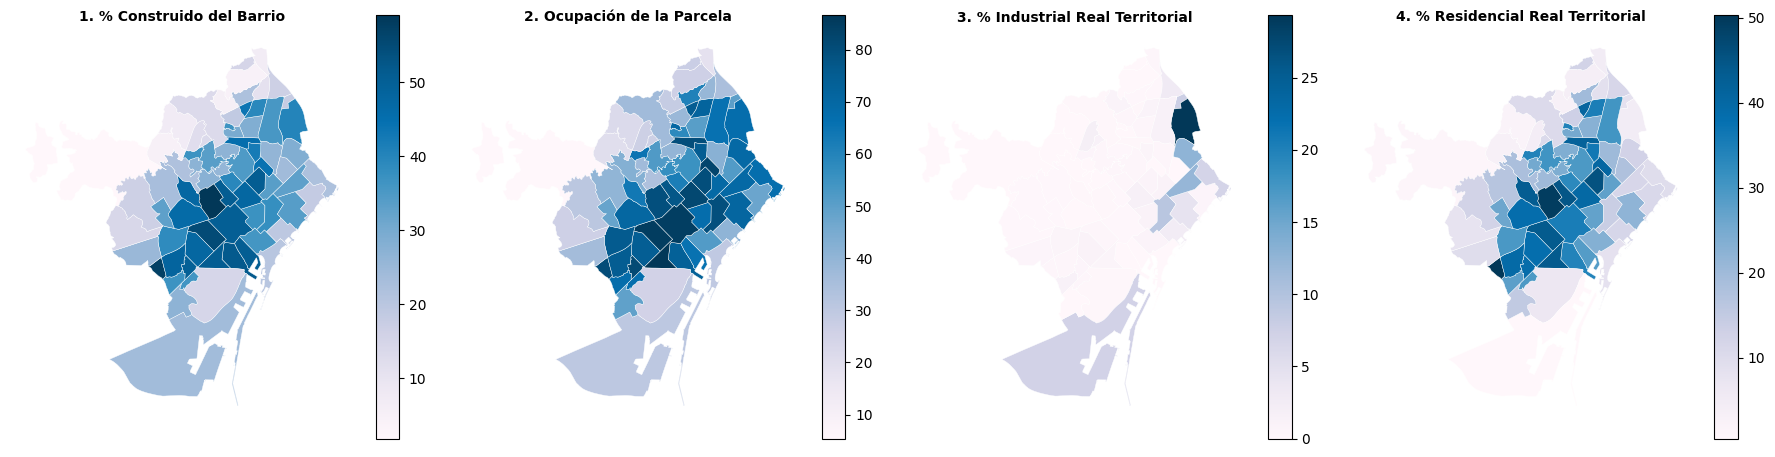

In [88]:
mapa = barrios.merge(tabla[['codi_barri'] + VARIABLES], on='codi_barri')

fig, ejes = plt.subplots(1, 4, figsize=(18, 5))
columnas_grafica = [
    ('pct_construido', '1. % Construido del Barrio'),
    ('pct_ocupacion_parcela', '2. Ocupación de la Parcela'),
    ('pct_industrial_real_barrio', '3. % Industrial Real Territorial'),
    ('pct_residencial_real_barrio', '4. % Residencial Real Territorial')
]

for i, (columna, titulo) in enumerate(columnas_grafica):
    mapa.plot(column=columna, cmap='PuBu', legend=True, ax=ejes[i], edgecolor='white', linewidth=0.3)
    ejes[i].set_title(titulo, fontsize=10, fontweight='bold')
    ejes[i].axis('off')

plt.tight_layout()
plt.show()

## **7. Guardamos la tabla**

Guardamos `codi_barri` + las variables, con una fila por barrio.

In [89]:
salida = tabla[['codi_barri'] + VARIABLES].round(2)
salida.to_csv(PROCESSED + 'edificacion_por_barrio.csv', index=False, encoding='utf-8-sig')

print('Guardado:', salida.shape)
display(salida.head())

Guardado: (73, 17)


,codi_barri,n_edificios,huella_total_m2,superficie_construida_m2,altura_media_m,pct_construido,edificabilidad,edificios_por_km2,pct_ocupacion_parcela,pct_residencial,pct_industrial,pct_servicios_publicos,pct_otros,pct_sin_dato,pct_residencial_real_barrio,pct_industrial_real_barrio,pct_servicios_publicos_real_barrio
0,1,1921,571019.20,2581461.14,13.56,51.90,2.35,1745.91,73.32,65.77,0.15,21.86,12.04,0.18,34.13,0.08,11.34
1,2,1322,413118.92,1949934.92,14.16,50.65,2.39,1620.90,65.58,56.62,0.04,21.90,20.62,0.83,28.68,0.02,11.09
2,3,929,239273.89,1011822.16,12.69,20.29,0.86,787.70,29.84,41.78,0.25,47.07,10.25,0.64,8.48,0.05,9.55
3,4,1514,399947.08,1812244.14,13.59,36.04,1.63,1364.37,51.56,65.12,2.47,22.66,9.68,0.08,23.47,0.89,8.17
4,5,677,344312.73,1934952.69,16.86,37.05,2.08,728.46,67.35,73.22,2.89,13.80,10.09,0.00,27.13,1.07,5.11
